In [14]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from pyproj import Geod
import numpy as np
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from tools import *
import math as ma
import matplotlib.gridspec as gridspec

In [15]:
def plot_adt_map_for_adcp(
    sat,
    lon,
    lat,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    vmin,
    vmax,
    lon_subset,
    lat_subset,
    depth_subset,
    x_dist,
    dx=50
):

    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    bathy = ax.contour(
        lon_subset,
        lat_subset,
        depth_subset,
        colors="grey",
        linewidths=0.8,
        transform=crs,
    )

    ax.clabel(bathy, fontsize=4)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat["adt"][0],
        levels=np.arange(vmin, vmax, 0.01),
        cmap="RdBu_r",
        transform=crs,
    )
    target_dists = np.arange(np.nanmin(x_dist), np.nanmax(x_dist), dx)  # km

    x_km = x_dist

    for d in target_dists:
        idx = np.argmin(np.abs(x_km - d))

        ax.text(
            lon[idx],
            lat[idx],
            f"{int(d)} km",
            transform=crs,
            fontsize=3,
            color="black",
            ha="left",
            va="bottom",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.2,
                alpha=0.8,
            ),
            zorder=120,
        )

    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    ax.scatter(
        lon,
        lat,
        s=0.5,
        color="green",
        transform=crs,
        zorder=90,
    )


    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("ADT [m]")

    return fig, ax

import numpy as np
from pyproj import Geod

def closest_x_distance(lon_point, lat_point, x_dist, lon_track, lat_track):
    """
    Find the along-track distance closest to a given lon/lat point.

    Parameters
    ----------
    lon_point : float
        Longitude of target point.
    lat_point : float
        Latitude of target point.
    x_dist : 1D array
        Along-track cumulative distance (same size as lon_track/lat_track).
        Units are preserved (e.g. meters).
    lon_track : 1D array
        Longitude along track.
    lat_track : 1D array
        Latitude along track.

    Returns
    -------
    x_closest : float
        Along-track distance corresponding to closest point.
    idx : int
        Index of closest track point.
    dist_min : float
        Distance from target point to track point (meters).
    """

    geod = Geod(ellps="WGS84")

    # Distance from target point to every point on the track
    _, _, distances = geod.inv(
        np.full_like(lon_track, lon_point),
        np.full_like(lat_track, lat_point),
        lon_track,
        lat_track
    )

    idx = np.argmin(np.abs(distances))

    return x_dist[idx]

In [16]:
dir_data = "/Volumes/science/MD252_WHIRLS/REP/data/"
dir_figures = "/Volumes/science/MD252_WHIRLS/REP/figures/"

dir_adcp = dir_data + "SADCP/WHIRLS_NB150_TOT_osite.nc"

dir_eddies = dir_data + f"Eddies/"
save_fig = dir_figures + f"/ADCP/"

adt_daily_dir = dir_data + "daily_adt/"

fname_bathy = dir_data + "bathymetry/etopo2.nc"

In [17]:
##### POSITION VARIABLES #####
jet = False
cyc = False
anti = True
if jet:
    lon_min, lon_max, lat_min, lat_max = 10, 14.5, -41, -36
    pos_west,pos_east,pos_south,pos_north  = 10, 14.5, -41,-36  #Reset the area
if cyc:
    lon_min, lon_max, lat_min, lat_max = 11, 16, -37, -35
    pos_west,pos_east,pos_south,pos_north  = 11, 16, -37,-35  #Reset the area
if anti:
    lon_min, lon_max, lat_min, lat_max = 9, 13.5, -39, -35
    pos_west,pos_east,pos_south,pos_north  = 9, 13.5, -39,-35  #Reset the area
ft=10

# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [18]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [19]:
daily_adt_files = sorted(os.listdir(adt_daily_dir))
adcp_data = xr.open_dataset(dir_adcp)

In [20]:
uvel_adcp = adcp_data.UVEL_ADCP
vvel_adcp = adcp_data.VVEL_ADCP
wvel_adcp = adcp_data.WVEL_ADCP
lon_adcp = adcp_data.LONGITUDE
lat_adcp = adcp_data.LATITUDE
depth_adcp = adcp_data.DEPH

ref_dat = adcp_data.REFERENCE_DATE_TIME
import numpy as np

ref = np.datetime64('1950-01-01T00:00:00')
t_adcp = adcp_data.JULD_ADCP
t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')
adcp_data['time'] = t_adcp 

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_38391/2138320484.py:13: UserWarning: Converting non-nanosecond precision timedelta values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')


In [21]:
new_adcp = xr.Dataset(
    data_vars={
        "uvel_adcp": (("time", "depth"), uvel_adcp.values),
        "vvel_adcp": (("time", "depth"), vvel_adcp.values),
        "wvel_adcp": (("time", "depth"), wvel_adcp.values),
        "lon_adcp": (("time"), lon_adcp.values),
        "lat_adcp": (("time"), lat_adcp.values),
    },
    coords={
        "time": t_adcp.values,
        "depth": depth_adcp.values,
    },
)

In [22]:
x_dist = along_track_distance(
    new_adcp.lon_adcp.values,
    new_adcp.lat_adcp.values
)

In [23]:
u = new_adcp.uvel_adcp.values
v = new_adcp.vvel_adcp.values

In [24]:
cyclone_data = {"n_eddy": 16, "x_min_adcp": 400, "x_max_adcp": 600, "date": "2026-07-01", "center": True}
jet_data = {"n_eddy": 16, "x_min_adcp": 400, "x_max_adcp": 720, "date": "2026-07-01", "center": True}
anti_cyclone_data1 = {"n_eddy": 13, "x_min_adcp": 600, "x_max_adcp": 725, "date": "2026-07-01", "center": False}
anti_cyclone_data2 = {"n_eddy": 12, "x_min_adcp": 760, "x_max_adcp": 840, "date": "2026-07-02", "center": True}
anti_cyclone_data3 = {"n_eddy": 12, "x_min_adcp": 860, "x_max_adcp": 950, "date": "2026-07-02", "center": False}
adcp_map = {"Cyclone": cyclone_data, "Anticyclone Cross1": anti_cyclone_data1, "Anticyclone Cross2": anti_cyclone_data2, "Anticyclone Cross3": anti_cyclone_data3}

(<Figure size 900x400 with 2 Axes>,
 <Axes: title={'center': 'Orthogonal Velocity Cyclone'}, xlabel='Distance [km]', ylabel='Depth [m]'>)

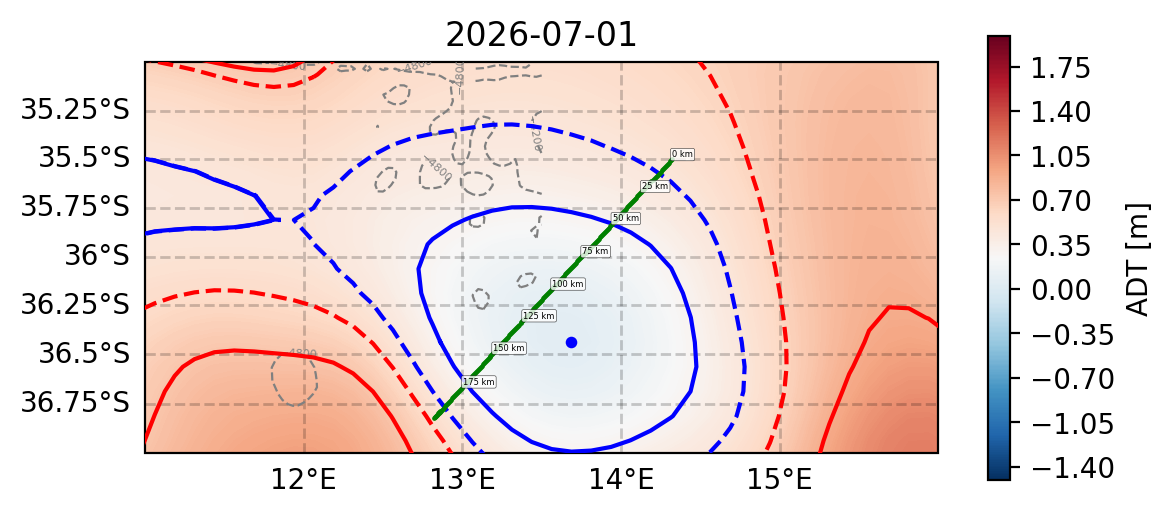

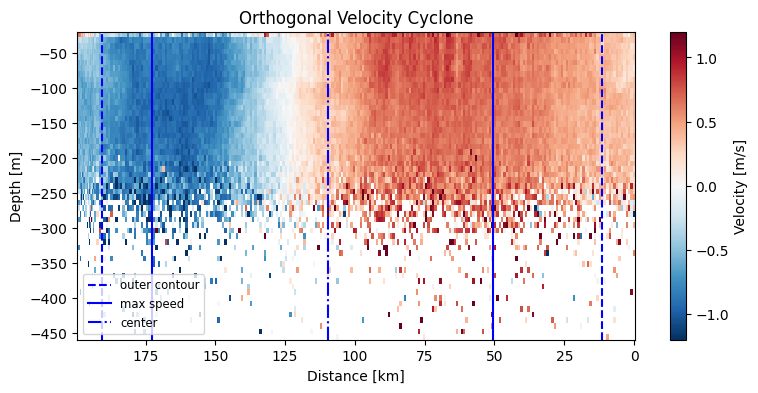

In [25]:
lon_min, lon_max, lat_min, lat_max = 11, 16, -37, -35
pos_west,pos_east,pos_south,pos_north  = 11, 16, -37,-35 
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent
sections = []

keys = ["Cyclone"]
v_orth_all = []
v_mag_all = []
x_all = []

results_ms_all = []
results_oc_all = []
results_cent = []

offset = 0
gap = 10      # km between sections

dist_masks = []
for key in keys:
    curr_cyc = adcp_map[key]
    n_eddy_cyc = curr_cyc["n_eddy"]
    x_min_cyc = curr_cyc["x_min_adcp"]
    x_max_cyc = curr_cyc["x_max_adcp"]
    curr_time_eddy = curr_cyc["date"]
    cent = curr_cyc["center"]

    curr_eddies = dir_eddies + curr_time_eddy
    anti, cyc = load_eddies(curr_eddies)

    file_adt = f"{curr_time_eddy}_cmems_data.nc"
    sat = load_satellite(adt_daily_dir + file_adt)

    eddies = anti if "Anti" in key else cyc

    dist_mask = get_x_dist_mask(new_adcp, x_dist, x_min_cyc, x_max_cyc)
    dist_masks.append(dist_mask)

    curr_adcp = new_adcp.isel(time=dist_mask)
    curr_xs = x_dist[dist_mask]

    results_oc = get_eddy_adcp_intersections(
        eddies["outcontour"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    results_ms = get_eddy_adcp_intersections(
        eddies["maxspeed"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    if cent:
        results_cent = determined_x_dist_of_center(
            eddies["centers"],
            n_eddy_cyc,
            curr_adcp,
            curr_xs
        )
    
    v_orth = orthogonal_velocity(
        curr_adcp,
        curr_xs
    )
    adcp_mag = velocity_magnitude(curr_adcp.uvel_adcp.values, curr_adcp.vvel_adcp.values)


    x = curr_xs / 1000

    v_orth_all.append(v_orth)
    v_mag_all.append(adcp_mag)
    x_all.append(x)

    results_ms_all.extend(results_ms)
    results_oc_all.extend(results_oc)

    if results_cent is not None:
        results_cent_all = results_cent

    sections.append({
        "x": x,
        "lon": curr_adcp.lon_adcp.values,
        "lat": curr_adcp.lat_adcp.values,
        "v_orth": v_orth,
        "v_mag": adcp_mag,
        "results_ms": results_ms,
        "results_oc": results_oc,
        "results_cent": results_cent
    })


# -----------------------------
# Glue sections together
# -----------------------------

x_plot_list = []
v_orth_plot_list = []
v_mag_plot_list = []
lons_list = []
lats_list = []
results_ms_all = []
results_oc_all = []
results_cent = []

offset = 0


for i in range(len(sections)):
    sec = sections[i]
    x = sec["x"]

    # new x coordinate starting at 0
    x_new = x - x[0] + offset

    x_plot_list.append(x_new)

    v_orth_plot_list.append(sec["v_orth"])
    v_mag_plot_list.append(sec["v_mag"])
    lons_list.append(sec["lon"])
    lats_list.append(sec["lat"])

    results_ms_all.extend(
        shift_results(
            sec["results_ms"],
            x[0],
            offset
        )
    )

    results_oc_all.extend(
        shift_results(
            sec["results_oc"],
            x[0],
            offset
        )
    )
    sec["results_cent"]["x_dist"]  = sec["results_cent"]["x_dist"]- x[0] + offset
    # next section starts after this one
    offset = x_new[-1]

# concatenate
x_plot = np.concatenate(x_plot_list)
lon_list = np.concatenate(lons_list)
lat_list = np.concatenate(lats_list)
v_orth_plot = np.concatenate(
    v_orth_plot_list,
    axis=0
)

v_mag_plot = np.concatenate(
    v_mag_plot_list,
    axis=0
)

# keep your logic
results_ms_all = [
    results_ms_all[0],
    results_ms_all[-1]
]
results_oc_all = [
    results_oc_all[0],
    results_oc_all[-1]
]


plot_adt_map_for_adcp(
    sat,
    lon_list,
    lat_list,
    anti,
    cyc,
    extent,
    curr_time_eddy,
    proj,
    crs,
    ft,
    -1.5,
    2,
    lon_subset,
    lat_subset,
    depth_subset,
    x_plot,
    dx=25) 

plot_adcp_section(
    new_adcp,               # only used for depth?
    v_orth_plot,
    x_plot,
    f"Orthogonal Velocity Cyclone",
    -1.2,
    1.2,
    cmap="RdBu_r",
    cyc = True,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=sec["results_cent"],
)

In [26]:
UU = curr_adcp.uvel_adcp.values
VV = curr_adcp.vvel_adcp.values

cmap = cmocean.cm.amp
WL_tmp= curr_adcp.lon_adcp.values[-1]
EL_tmp= curr_adcp.lon_adcp.values[0]
NL_tmp = curr_adcp.lat_adcp.values[0]
SL_tmp= curr_adcp.lat_adcp.values[-1]
Size_Grid=[50,50]
lon_lat_centers = []
x_dist_centers = []
for i in range(len(curr_adcp.depth.values)): # for i in range(len(curr_adcp.depth.values)) ?
    
    #Pour avoir la profondeur donnée
    #depth_tmp = i
    print(i/2)
    Lon_tmp= curr_adcp.lon_adcp.values
    Lat_tmp=curr_adcp.lat_adcp.values
    U_tmp= UU[:,i] #U[:,id_Depth_targ] si on vise une profondeur 
    V_tmp= VV[:,i] #V[:,id_Depth_targ]
    
    # 
    id_out = np.where((Lon_tmp>EL_tmp) & (Lon_tmp<WL_tmp) 
                      & (Lat_tmp>NL_tmp) & (Lat_tmp<SL_tmp))[0]
    #print(id_out)
    Lon_tmp[id_out]=np.nan
    Lat_tmp[id_out]=np.nan
    U_tmp[id_out]=np.nan
    V_tmp[id_out]=np.nan
    #print(U_tmp)
    '''
    for id_nan in np.where((np.isnan(U_tmp)))[0] :
        print(id_nan)
        id_non_nanbef = np.where((np.isnan(U_tmp[0:id_nan])==0))[0][-1]
        #print(id_non_nanbef)
        id_non_nanaft = id_nan + np.where((np.isnan(U_tmp[id_nan:])==0))[0][0]
        #print(id_non_nanaft)
        U_tmp[id_nan]=np.interp(id_nan,[id_non_nanbef,id_non_nanaft],[U_tmp[id_non_nanbef],U_tmp[id_non_nanaft]])
        V_tmp[id_nan]=np.interp(id_nan,[id_non_nanbef,id_non_nanaft],[V_tmp[id_non_nanbef],V_tmp[id_non_nanaft]])
    '''
    #Estimate_Eddycenter_Nencioli(WL_tmp,EL_tmp,SL_tmp,NL_tmp,\
    #    Lon_tmp,Lat_tmp,U_tmp,V_tmp,Size_Grid)
    
    WL = WL_tmp
    EL = EL_tmp
    SL = SL_tmp
    NL = NL_tmp
    x_vel = Lon_tmp
    y_vel = Lat_tmp
    U_ADCP = U_tmp
    V_ADCP = V_tmp
    
    if Size_Grid[0]==1 | Size_Grid[1]==1 :
            Size_Grid=[Size_Grid,Size_Grid]
        
    #lon=WL:(EL-WL)/(Size_Grid[0]-1):EL
    lon2 = np.arange(WL,EL,(EL-WL)/(Size_Grid[0]-1))
    #lat=SL:(NL-SL)/(Size_Grid[1]-1):NL;
    lat2 = np.arange(SL,NL,(NL-SL)/(Size_Grid[1]-1))
    #print(lat)
    R=6378 # Earth radius
    f=np.pi/180 # angle converting factor from degree to radians
    
    #Declare variables
    A = np.zeros(x_vel.shape[0])
    A[:] = np.nan
    radial = A
    alpha = radial
    tangent = radial
    B = np.zeros((len(lat2),len(lon2)))
    B[:,:] = np.nan
    Elliptic_Mtg = B
    Elliptic_RMS = Elliptic_Mtg
    cnt = 0
    for ii in range(len(lon2)) : #for every longitude of the square
        #print(ii)
        for iii in range(len(lat2)) :#for every latitude of the square
            s = 0
            for j in range(len(x_vel)) : #for every velocity measured along the transect
     #Decompose velocities along the transect into tangential and radial components
     #assuming the point(ii,iii) within the square as the eddy center %
            
     #Compute the distance between the point(ii,iii) within the square
     #and the point(j) where velocities were measured
     
                 #(distance between points on a sphere)           
                 #r[ii]=R*ma.acos(ma.cos(lat[iii]f)*ma.cos(y_vel[j]*f) \
                #ma.cos(lon[ii]*f-x_vel[j]*f)+ma.sin(lat[iii]*f)*ma.sin(y_vel[j]*f))
                 
                 #Compute angle between the point(ii,iii) within the square 
                 #and the point(j) where velocities were measured
                dy = R * ma.acos(
                    ma.cos(lat2[iii]) * ma.cos(y_vel[j]) *
                    ma.cos(lon2[ii] - lon2[ii]) +
                    ma.sin(lat2[iii]) * ma.sin(y_vel[j])
                )

                dx = R * ma.acos(
                    ma.cos(y_vel[j]) * ma.cos(y_vel[j]) *
                    ma.cos(lon2[ii] - x_vel[j]) +
                    ma.sin(y_vel[j]) * ma.sin(y_vel[j])
                )
                angle = np.arctan2(dy, dx)
                
                # angle = ma.atan(dy/dx)
                 #Adjust the angle value depending on the quadrant position of the points
                if (lon2[ii]>x_vel[j]) & (lat2[iii]<y_vel[j]) :
                     angle=np.pi-angle
                elif (lon2[ii]>x_vel[j]) & (lat2[iii]>y_vel[j]) :
                     angle=np.pi+angle
                elif (lon2[ii]<x_vel[j]) & (lat2[iii]>y_vel[j]) :
                     angle=2*np.pi-angle
                 
                alpha[j]=angle*180/np.pi
                
                # Compute RMS of the radial component and % Mean of the tangential component
                # the COE will be, respectivelly, the smallest and largest point of
                # these grids.                
                radial[j]=U_ADCP[j]*ma.cos(angle)+V_ADCP[j]*ma.sin(angle)
                tangent[j]=-U_ADCP[j]*ma.sin(angle)+V_ADCP[j]*ma.cos(angle)
                if np.isnan(radial[j])==0 :
                     s = s + (radial[j])**2
            cnt += 1
            Elliptic_RMS[iii,ii]=np.sqrt(s)/np.sqrt(len(radial))
            Elliptic_Mtg[iii,ii]=np.nanmean(tangent)
    
    
    [Elliptic_Lon,Elliptic_Lat]=np.meshgrid(lon2,lat2)
    m_elli_rms = Elliptic_RMS.min()
    id_min_RMS = np.where((Elliptic_RMS==m_elli_rms))[0]
    m_elli_mtg = Elliptic_Mtg.max()
    id_max_Mtg = np.where((Elliptic_Mtg==m_elli_mtg))[0]
    print(lon2[id_min_RMS])
    print(lat2[id_min_RMS])
    lon_lat_centers.append((lon2[id_min_RMS], lat2[id_min_RMS]))
    x_dist_centers.append(closest_x_distance(lon2[id_min_RMS], lat2[id_min_RMS], x_plot, curr_adcp.lon_adcp.values, curr_adcp.lat_adcp.values))


0.0
[13.5883007]
[-36.14743423]
0.5
[13.31326485]
[-36.39030075]
1.0
[13.31326485]
[-36.39030075]
1.5
[13.31326485]
[-36.39030075]
2.0
[13.31326485]
[-36.39030075]
2.5
[13.31326485]
[-36.39030075]
3.0
[13.31326485]
[-36.39030075]
3.5
[13.31326485]
[-36.39030075]
4.0
[13.28270531]
[-36.41728592]
4.5
[13.28270531]
[-36.41728592]
5.0
[13.28270531]
[-36.41728592]
5.5
[13.28270531]
[-36.41728592]
6.0
[13.28270531]
[-36.41728592]
6.5
[13.28270531]
[-36.41728592]
7.0
[13.28270531]
[-36.41728592]
7.5
[13.28270531]
[-36.41728592]
8.0
[13.28270531]
[-36.41728592]
8.5
[13.28270531]
[-36.41728592]
9.0
[13.28270531]
[-36.41728592]
9.5
[13.28270531]
[-36.41728592]
10.0
[13.28270531]
[-36.41728592]
10.5
[13.28270531]
[-36.41728592]
11.0
[13.28270531]
[-36.41728592]
11.5
[13.28270531]
[-36.41728592]
12.0
[13.28270531]
[-36.41728592]
12.5
[13.28270531]
[-36.41728592]
13.0
[13.28270531]
[-36.41728592]
13.5
[13.28270531]
[-36.41728592]
14.0
[13.28270531]
[-36.41728592]
14.5
[13.28270531]
[-36.41728592]
1

In [28]:
def plot_adcp_section2(curr_day, adcp_mag, x_dist, title, vmin, vmax, cmap="viridis", cyc = True, results_oc=None, results_ms=None, eddy_center_toeddies=None, eddy_center_nencioli=None, savefig=None):

    fig, ax = plt.subplots(figsize=(9,4))

    c = ax.pcolormesh(
        x_dist,
        curr_day.depth.values,
        adcp_mag.T,
        vmin = vmin,
        vmax = vmax,
        cmap=cmap
    )
    if cyc:
        col = 'blue'
    else:
        col = 'red'
    if results_oc is not None:
        for result in results_oc:
            ax.axvline(result["x_dist"], color=col, linestyle='--')
    if results_ms is not None:
        for result in results_ms:
            ax.axvline(result["x_dist"], color=col, linestyle='solid')
    if eddy_center_toeddies is not None:
        ax.axvline(eddy_center_toeddies["x_dist"], color=col, linestyle='dashdot')

    if eddy_center_nencioli is not None:
        ax.plot(eddy_center_nencioli, curr_day.depth.values, color='g', linestyle='dashdot')
    ax.set_ylim(-250, 0)
    ax.invert_xaxis()
    cbar = fig.colorbar(c, ax=ax)
    cbar.set_label("Velocity [m/s]")
    from matplotlib.lines import Line2D

    legend_handles = [
        Line2D([0], [0], color=col, linestyle='--', label="outer contour"),
        Line2D([0], [0], color=col, linestyle='solid', label='max speed'),
        Line2D([0], [0], color=col, linestyle='dashdot', label='TOEddies center'),
        Line2D([0], [0], color="g", linestyle='dashdot', label='Nencioli center')
    ]

    leg = ax.legend(
        handles=legend_handles,
        loc="lower left",
        fontsize="small",
        frameon=True,
    )
    ax.set_xlabel("Distance [km]")
    ax.set_ylabel("Depth [m]")
    ax.set_title(title)
    if savefig is not None:
        plt.savefig(savefig)
    return fig, ax

(<Figure size 900x400 with 2 Axes>,
 <Axes: title={'center': 'Orthogonal Velocity Cyclone'}, xlabel='Distance [km]', ylabel='Depth [m]'>)

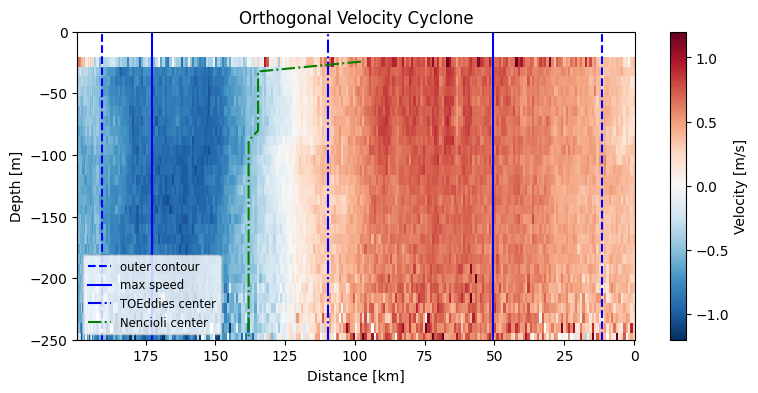

In [29]:
plot_adcp_section2(
    new_adcp,               # only used for depth?
    v_orth_plot,
    x_plot,
    f"Orthogonal Velocity Cyclone",
    -1.2,
    1.2,
    cmap="RdBu_r",
    cyc = True,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=sec["results_cent"],
    eddy_center_nencioli=x_dist_centers
)

(<Figure size 900x400 with 2 Axes>,
 <Axes: title={'center': 'Vertical Velocity Anticyclone'}, xlabel='Distance [km]', ylabel='Depth [m]'>)

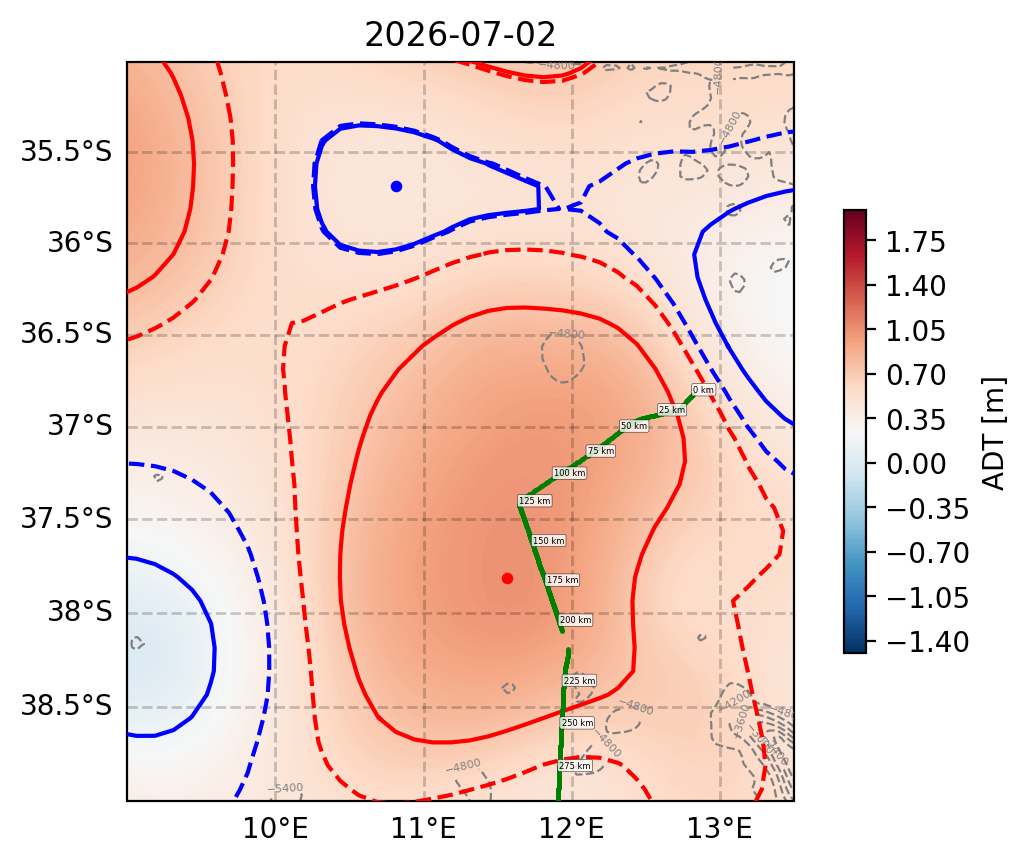

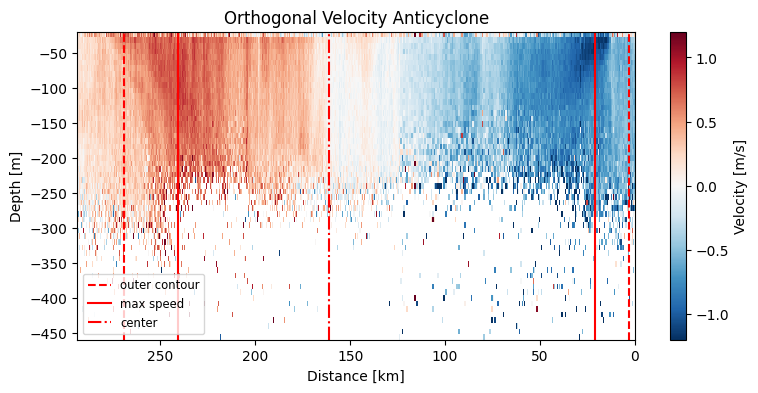

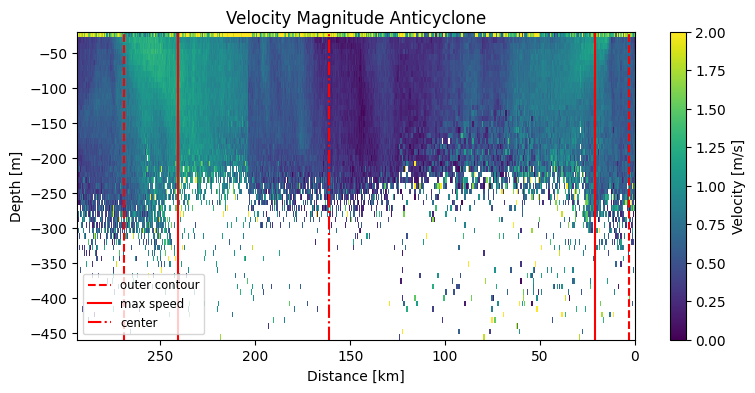

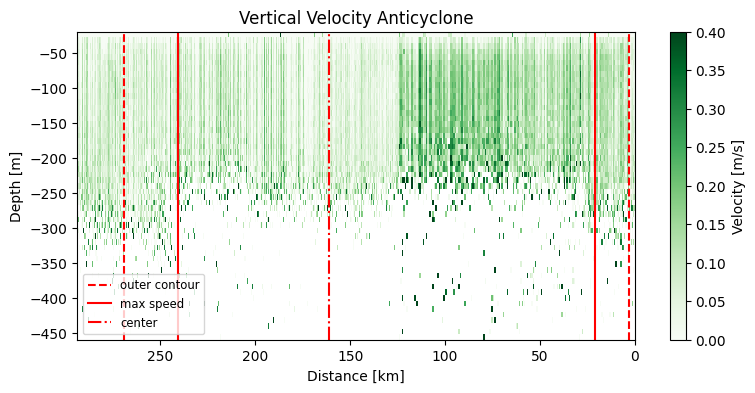

In [30]:
lon_min, lon_max, lat_min, lat_max = 9, 13.5, -39, -35
pos_west,pos_east,pos_south,pos_north  = 9, 13.5, -39,-35 
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent
sections = []

keys = ["Anticyclone Cross1", "Anticyclone Cross2", "Anticyclone Cross3"]
v_orth_all = []
v_mag_all = []
x_all = []

results_ms_all = []
results_oc_all = []
results_cent = []

offset = 0
gap = 10      # km between sections

dist_masks = []
w_vel_all = []
for key in keys:
    curr_cyc = adcp_map[key]
    n_eddy_cyc = curr_cyc["n_eddy"]
    x_min_cyc = curr_cyc["x_min_adcp"]
    x_max_cyc = curr_cyc["x_max_adcp"]
    curr_time_eddy = curr_cyc["date"]
    cent = curr_cyc["center"]

    curr_eddies = dir_eddies + curr_time_eddy
    anti, cyc = load_eddies(curr_eddies)

    file_adt = f"{curr_time_eddy}_cmems_data.nc"
    sat = load_satellite(adt_daily_dir + file_adt)

    eddies = anti if "Anti" in key else cyc

    dist_mask = get_x_dist_mask(new_adcp, x_dist, x_min_cyc, x_max_cyc)
    dist_masks.append(dist_mask)

    curr_adcp = new_adcp.isel(time=dist_mask)
    curr_xs = x_dist[dist_mask]

    results_oc = get_eddy_adcp_intersections(
        eddies["outcontour"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    results_ms = get_eddy_adcp_intersections(
        eddies["maxspeed"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    if cent:
        results_cent = determined_x_dist_of_center(
            eddies["centers"],
            n_eddy_cyc,
            curr_adcp,
            curr_xs
        )
    
    v_orth = orthogonal_velocity(
        curr_adcp,
        curr_xs
    )
    adcp_mag = velocity_magnitude(curr_adcp.uvel_adcp.values, curr_adcp.vvel_adcp.values)

    x = curr_xs / 1000

    v_orth_all.append(v_orth)
    v_mag_all.append(adcp_mag)
    x_all.append(x)

    results_ms_all.extend(results_ms)
    results_oc_all.extend(results_oc)

    if results_cent is not None:
        results_cent_all = results_cent

    sections.append({
        "x": x,
        "lon": curr_adcp.lon_adcp.values,
        "lat": curr_adcp.lat_adcp.values,
        "v_orth": v_orth,
        "w_vel": curr_adcp.wvel_adcp.values,
        "v_mag": adcp_mag,
        "results_ms": results_ms,
        "results_oc": results_oc,
        "results_cent": results_cent
    })


# -----------------------------
# Glue sections together
# -----------------------------

x_plot_list = []
v_orth_plot_list = []
v_mag_plot_list = []
lons_list = []
lats_list = []
results_ms_all = []
results_oc_all = []
results_cent = []
w_vel_all = []
offset = 0


for i in range(len(sections)):
    sec = sections[i]
    x = sec["x"]

    # new x coordinate starting at 0
    x_new = x - x[0] + offset

    x_plot_list.append(x_new)

    v_orth_plot_list.append(sec["v_orth"])
    v_mag_plot_list.append(sec["v_mag"])
    lons_list.append(sec["lon"])
    lats_list.append(sec["lat"])
    w_vel_all.append(sec["w_vel"])

    results_ms_all.extend(
        shift_results(
            sec["results_ms"],
            x[0],
            offset
        )
    )

    results_oc_all.extend(
        shift_results(
            sec["results_oc"],
            x[0],
            offset
        )
    )
    if i == 1:
        sec["results_cent"]["x_dist"]  = sec["results_cent"]["x_dist"]- x[0] + offset
        results_cent = sec["results_cent"]
    # next section starts after this one
    offset = x_new[-1]

# concatenate
x_plot = np.concatenate(x_plot_list)
lon_list = np.concatenate(lons_list)
lat_list = np.concatenate(lats_list)
w_vel_list = np.concatenate(w_vel_all)

v_orth_plot = np.concatenate(
    v_orth_plot_list,
    axis=0
)

v_mag_plot = np.concatenate(
    v_mag_plot_list,
    axis=0
)

# keep your logic
results_ms_all = [
    results_ms_all[0],
    results_ms_all[-1]
]
results_oc_all = [
    results_oc_all[0],
    results_oc_all[-1]
]

plot_adt_map_for_adcp(
    sat,
    lon_list,
    lat_list,
    anti,
    cyc,
    extent,
    curr_time_eddy,
    proj,
    crs,
    ft,
    -1.5,
    2,
    lon_subset,
    lat_subset,
    depth_subset,
    x_plot,
    dx=25)
 
plot_adcp_section(
    new_adcp,               # only used for depth?
    v_orth_plot,
    x_plot,
    f"Orthogonal Velocity Anticyclone",
    -1.2,
    1.2,
    cmap="RdBu_r",
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=results_cent,
)

plot_adcp_section(
    new_adcp,               # only used for depth?
    v_mag_plot,
    x_plot,
    f"Velocity Magnitude Anticyclone",
    0,
    2,
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=results_cent,
)


plot_adcp_section(
    new_adcp,               # only used for depth?
    w_vel_list,
    x_plot,
    f"Vertical Velocity Anticyclone",
    0,
    0.4,
    cmap="Greens",
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=results_cent,
)

In [ ]:
UU = curr_adcp.uvel_adcp.values
VV = curr_adcp.vvel_adcp.values

cmap = cmocean.cm.amp
WL_tmp= curr_adcp.lon_adcp.values[-1]
EL_tmp= curr_adcp.lon_adcp.values[0]
NL_tmp = curr_adcp.lat_adcp.values[0]
SL_tmp= curr_adcp.lat_adcp.values[-1]
Size_Grid=[50,50]
lon_lat_centers = []
x_dist_centers = []
for i in range(len(curr_adcp.depth.values)): # for i in range(len(curr_adcp.depth.values)) ?
    
    #Pour avoir la profondeur donnée
    #depth_tmp = i
    print(i/2)
    Lon_tmp= curr_adcp.lon_adcp.values
    Lat_tmp=curr_adcp.lat_adcp.values
    U_tmp= UU[:,i] #U[:,id_Depth_targ] si on vise une profondeur 
    V_tmp= VV[:,i] #V[:,id_Depth_targ]
    
    # 
    id_out = np.where((Lon_tmp>EL_tmp) & (Lon_tmp<WL_tmp) 
                      & (Lat_tmp>NL_tmp) & (Lat_tmp<SL_tmp))[0]
    #print(id_out)
    Lon_tmp[id_out]=np.nan
    Lat_tmp[id_out]=np.nan
    U_tmp[id_out]=np.nan
    V_tmp[id_out]=np.nan
    #print(U_tmp)
    '''
    for id_nan in np.where((np.isnan(U_tmp)))[0] :
        print(id_nan)
        id_non_nanbef = np.where((np.isnan(U_tmp[0:id_nan])==0))[0][-1]
        #print(id_non_nanbef)
        id_non_nanaft = id_nan + np.where((np.isnan(U_tmp[id_nan:])==0))[0][0]
        #print(id_non_nanaft)
        U_tmp[id_nan]=np.interp(id_nan,[id_non_nanbef,id_non_nanaft],[U_tmp[id_non_nanbef],U_tmp[id_non_nanaft]])
        V_tmp[id_nan]=np.interp(id_nan,[id_non_nanbef,id_non_nanaft],[V_tmp[id_non_nanbef],V_tmp[id_non_nanaft]])
    '''
    #Estimate_Eddycenter_Nencioli(WL_tmp,EL_tmp,SL_tmp,NL_tmp,\
    #    Lon_tmp,Lat_tmp,U_tmp,V_tmp,Size_Grid)
    
    WL = WL_tmp
    EL = EL_tmp
    SL = SL_tmp
    NL = NL_tmp
    x_vel = Lon_tmp
    y_vel = Lat_tmp
    U_ADCP = U_tmp
    V_ADCP = V_tmp
    
    if Size_Grid[0]==1 | Size_Grid[1]==1 :
            Size_Grid=[Size_Grid,Size_Grid]
        
    #lon=WL:(EL-WL)/(Size_Grid[0]-1):EL
    lon2 = np.arange(WL,EL,(EL-WL)/(Size_Grid[0]-1))
    #lat=SL:(NL-SL)/(Size_Grid[1]-1):NL;
    lat2 = np.arange(SL,NL,(NL-SL)/(Size_Grid[1]-1))
    #print(lat)
    R=6378 # Earth radius
    f=np.pi/180 # angle converting factor from degree to radians
    
    #Declare variables
    A = np.zeros(x_vel.shape[0])
    A[:] = np.nan
    radial = A
    alpha = radial
    tangent = radial
    B = np.zeros((len(lat2),len(lon2)))
    B[:,:] = np.nan
    Elliptic_Mtg = B
    Elliptic_RMS = Elliptic_Mtg
    cnt = 0
    for ii in range(len(lon2)) : #for every longitude of the square
        #print(ii)
        for iii in range(len(lat2)) :#for every latitude of the square
            s = 0
            for j in range(len(x_vel)) : #for every velocity measured along the transect
     #Decompose velocities along the transect into tangential and radial components
     #assuming the point(ii,iii) within the square as the eddy center %
            
     #Compute the distance between the point(ii,iii) within the square
     #and the point(j) where velocities were measured
     
                 #(distance between points on a sphere)           
                 #r[ii]=R*ma.acos(ma.cos(lat[iii]f)*ma.cos(y_vel[j]*f) \
                #ma.cos(lon[ii]*f-x_vel[j]*f)+ma.sin(lat[iii]*f)*ma.sin(y_vel[j]*f))
                 
                 #Compute angle between the point(ii,iii) within the square 
                 #and the point(j) where velocities were measured
                dy = R * ma.acos(
                    ma.cos(lat2[iii]) * ma.cos(y_vel[j]) *
                    ma.cos(lon2[ii] - lon2[ii]) +
                    ma.sin(lat2[iii]) * ma.sin(y_vel[j])
                )

                dx = R * ma.acos(
                    ma.cos(y_vel[j]) * ma.cos(y_vel[j]) *
                    ma.cos(lon2[ii] - x_vel[j]) +
                    ma.sin(y_vel[j]) * ma.sin(y_vel[j])
                )
                angle = np.arctan2(dy, dx)
                
                # angle = ma.atan(dy/dx)
                 #Adjust the angle value depending on the quadrant position of the points
                if (lon2[ii]>x_vel[j]) & (lat2[iii]<y_vel[j]) :
                     angle=np.pi-angle
                elif (lon2[ii]>x_vel[j]) & (lat2[iii]>y_vel[j]) :
                     angle=np.pi+angle
                elif (lon2[ii]<x_vel[j]) & (lat2[iii]>y_vel[j]) :
                     angle=2*np.pi-angle
                 
                alpha[j]=angle*180/np.pi
                
                # Compute RMS of the radial component and % Mean of the tangential component
                # the COE will be, respectivelly, the smallest and largest point of
                # these grids.                
                radial[j]=U_ADCP[j]*ma.cos(angle)+V_ADCP[j]*ma.sin(angle)
                tangent[j]=-U_ADCP[j]*ma.sin(angle)+V_ADCP[j]*ma.cos(angle)
                if np.isnan(radial[j])==0 :
                     s = s + (radial[j])**2
            cnt += 1
            Elliptic_RMS[iii,ii]=np.sqrt(s)/np.sqrt(len(radial))
            Elliptic_Mtg[iii,ii]=np.nanmean(tangent)
    
    
    [Elliptic_Lon,Elliptic_Lat]=np.meshgrid(lon2,lat2)
    m_elli_rms = Elliptic_RMS.min()
    id_min_RMS = np.where((Elliptic_RMS==m_elli_rms))[0]
    m_elli_mtg = Elliptic_Mtg.max()
    id_max_Mtg = np.where((Elliptic_Mtg==m_elli_mtg))[0]
    print(lon2[id_min_RMS])
    print(lat2[id_min_RMS])
    lon_lat_centers.append((lon2[id_min_RMS], lat2[id_min_RMS]))
    x_dist_centers.append(closest_x_distance(lon2[id_min_RMS], lat2[id_min_RMS], x_plot, curr_adcp.lon_adcp.values, curr_adcp.lat_adcp.values))


0.0
[11.9109869]
[-38.95314407]
0.5


In [ ]:
plot_adcp_section2(
    new_adcp,               # only used for depth?
    v_orth_plot,
    x_plot,
    f"Orthogonal Velocity Anticyclone",
    -1.2,
    1.2,
    cmap="RdBu_r",
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=sec["results_cent"],
    eddy_center_nencioli=x_dist_centers
)